In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

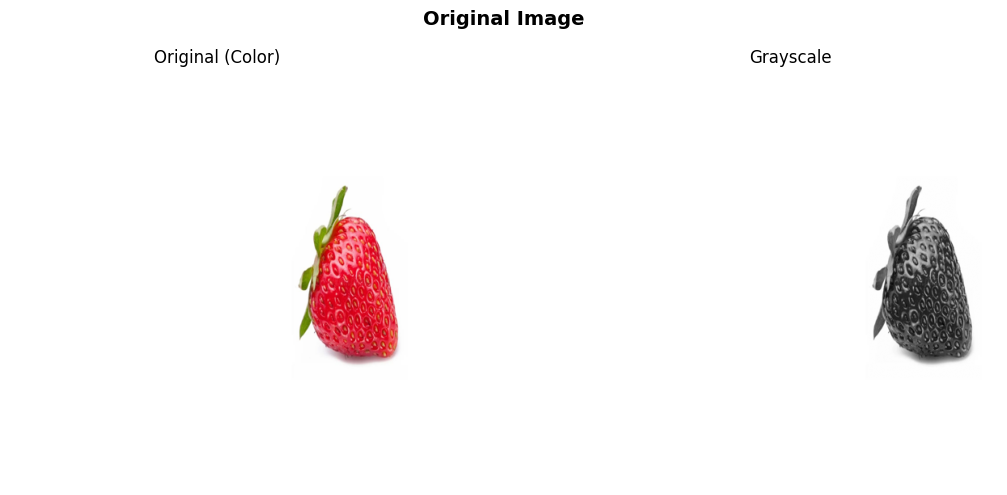

In [ ]:
img = np.array(Image.open("orangestraw.jpg").convert("RGB").resize((512, 512)))
img_gray = np.array(Image.open("orangestraw.jpg").convert("L").resize((512, 512)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Original Image", fontsize=14, fontweight='bold')

axes[0].imshow(img)
axes[0].set_title("Original (Color)")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("Grayscale")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("original.png", dpi=150, bbox_inches='tight')
plt.show()

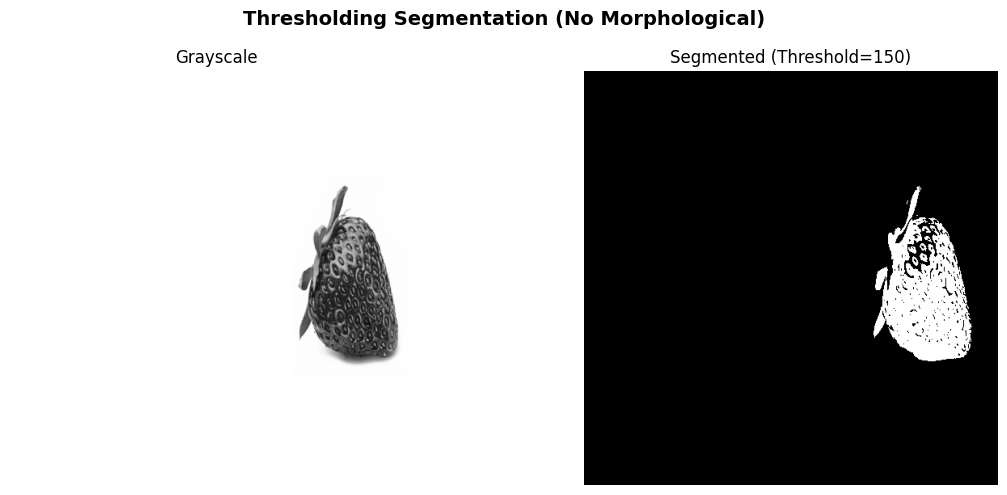

In [ ]:
def threshold(img_gray, threshold_value=127):
    result = np.zeros_like(img_gray)
    for i in range(img_gray.shape[0]):
        for j in range(img_gray.shape[1]):
            if img_gray[i, j] < threshold_value:
                result[i, j] = 255
            else:
                result[i, j] = 0
    return result

segmented = threshold(img_gray, threshold_value=150)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Thresholding Segmentation (No Morphological)", fontsize=14, fontweight='bold')

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Grayscale")
axes[0].axis('off')

axes[1].imshow(segmented, cmap='gray')
axes[1].set_title("Segmented (Threshold=150)")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("segmented.png", dpi=150, bbox_inches='tight')
plt.show()

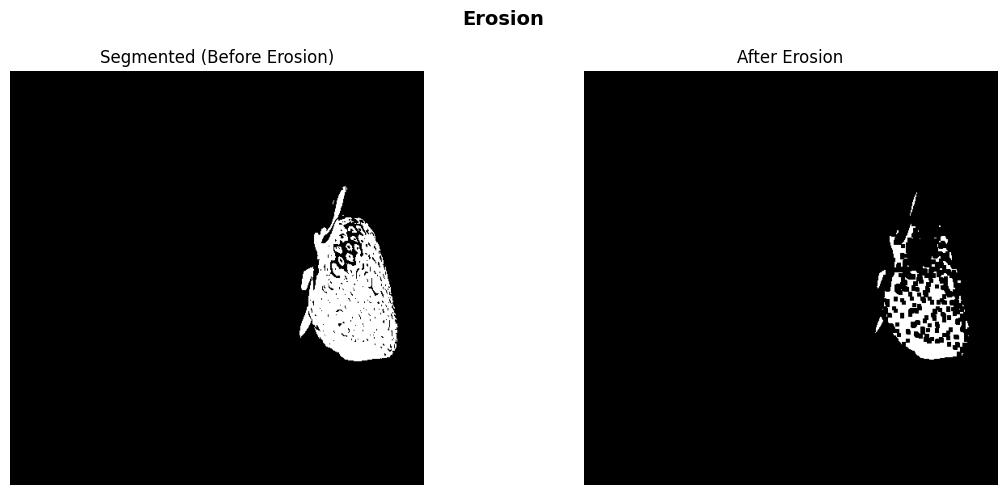

In [ ]:
def erosion(img_binary, kernel_size=3):
    pad = kernel_size // 2
    result = np.zeros_like(img_binary)
    for i in range(pad, img_binary.shape[0] - pad):
        for j in range(pad, img_binary.shape[1] - pad):
            region = img_binary[i-pad:i+pad+1, j-pad:j+pad+1]
            if np.all(region == 255):
                result[i, j] = 255
    return result

eroded = erosion(segmented, kernel_size=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Erosion", fontsize=14, fontweight='bold')

axes[0].imshow(segmented, cmap='gray')
axes[0].set_title("Segmented (Before Erosion)")
axes[0].axis('off')

axes[1].imshow(eroded, cmap='gray')
axes[1].set_title("After Erosion")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("erosion.png", dpi=150, bbox_inches='tight')
plt.show()

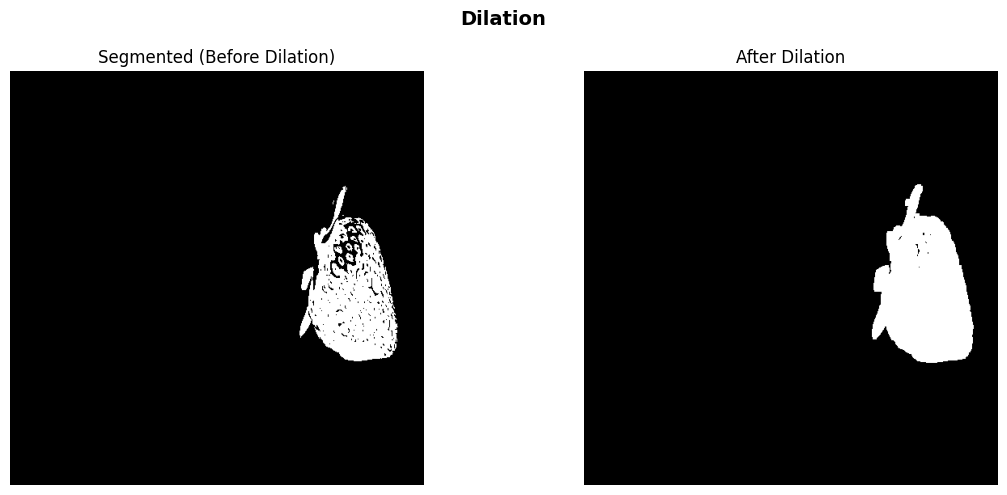

In [ ]:
def dilation(img_binary, kernel_size=3):
    pad = kernel_size // 2
    result = np.zeros_like(img_binary)
    for i in range(pad, img_binary.shape[0] - pad):
        for j in range(pad, img_binary.shape[1] - pad):
            region = img_binary[i-pad:i+pad+1, j-pad:j+pad+1]
            if np.any(region == 255):
                result[i, j] = 255
    return result

dilated = dilation(segmented, kernel_size=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Dilation", fontsize=14, fontweight='bold')

axes[0].imshow(segmented, cmap='gray')
axes[0].set_title("Segmented (Before Dilation)")
axes[0].axis('off')

axes[1].imshow(dilated, cmap='gray')
axes[1].set_title("After Dilation")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("dilation.png", dpi=150, bbox_inches='tight')
plt.show()

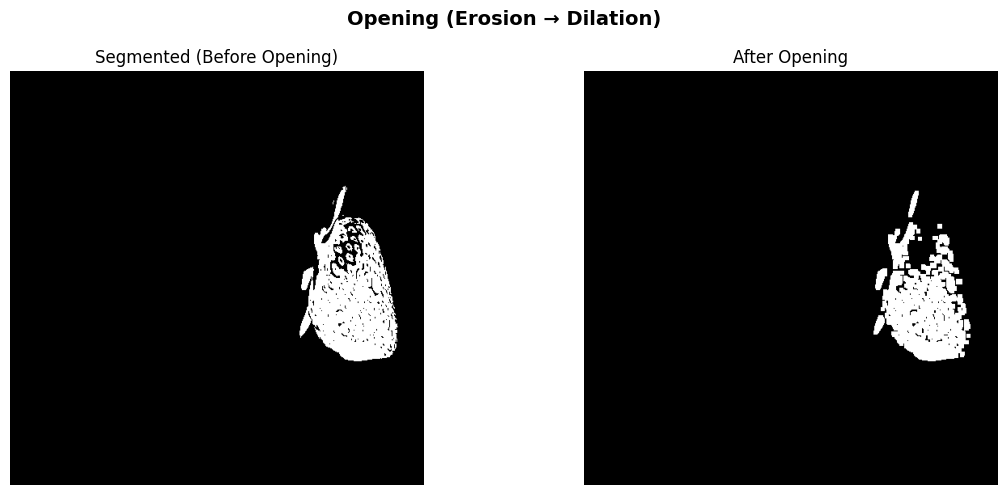

In [ ]:
def opening(img_binary, kernel_size=3):
    return dilation(erosion(img_binary, kernel_size), kernel_size)

opened = opening(segmented, kernel_size=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Opening (Erosion → Dilation)", fontsize=14, fontweight='bold')

axes[0].imshow(segmented, cmap='gray')
axes[0].set_title("Segmented (Before Opening)")
axes[0].axis('off')

axes[1].imshow(opened, cmap='gray')
axes[1].set_title("After Opening")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("opening.png", dpi=150, bbox_inches='tight')
plt.show()

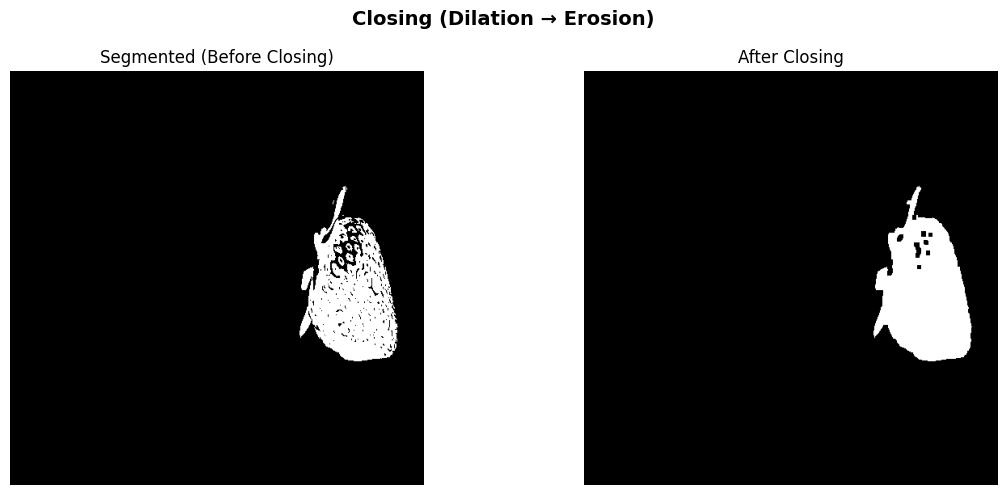

In [ ]:
def closing(img_binary, kernel_size=3):
    return erosion(dilation(img_binary, kernel_size), kernel_size)

closed = closing(segmented, kernel_size=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Closing (Dilation → Erosion)", fontsize=14, fontweight='bold')

axes[0].imshow(segmented, cmap='gray')
axes[0].set_title("Segmented (Before Closing)")
axes[0].axis('off')

axes[1].imshow(closed, cmap='gray')
axes[1].set_title("After Closing")
axes[1].axis('off')

plt.tight_layout()
plt.savefig("closing.png", dpi=150, bbox_inches='tight')
plt.show()

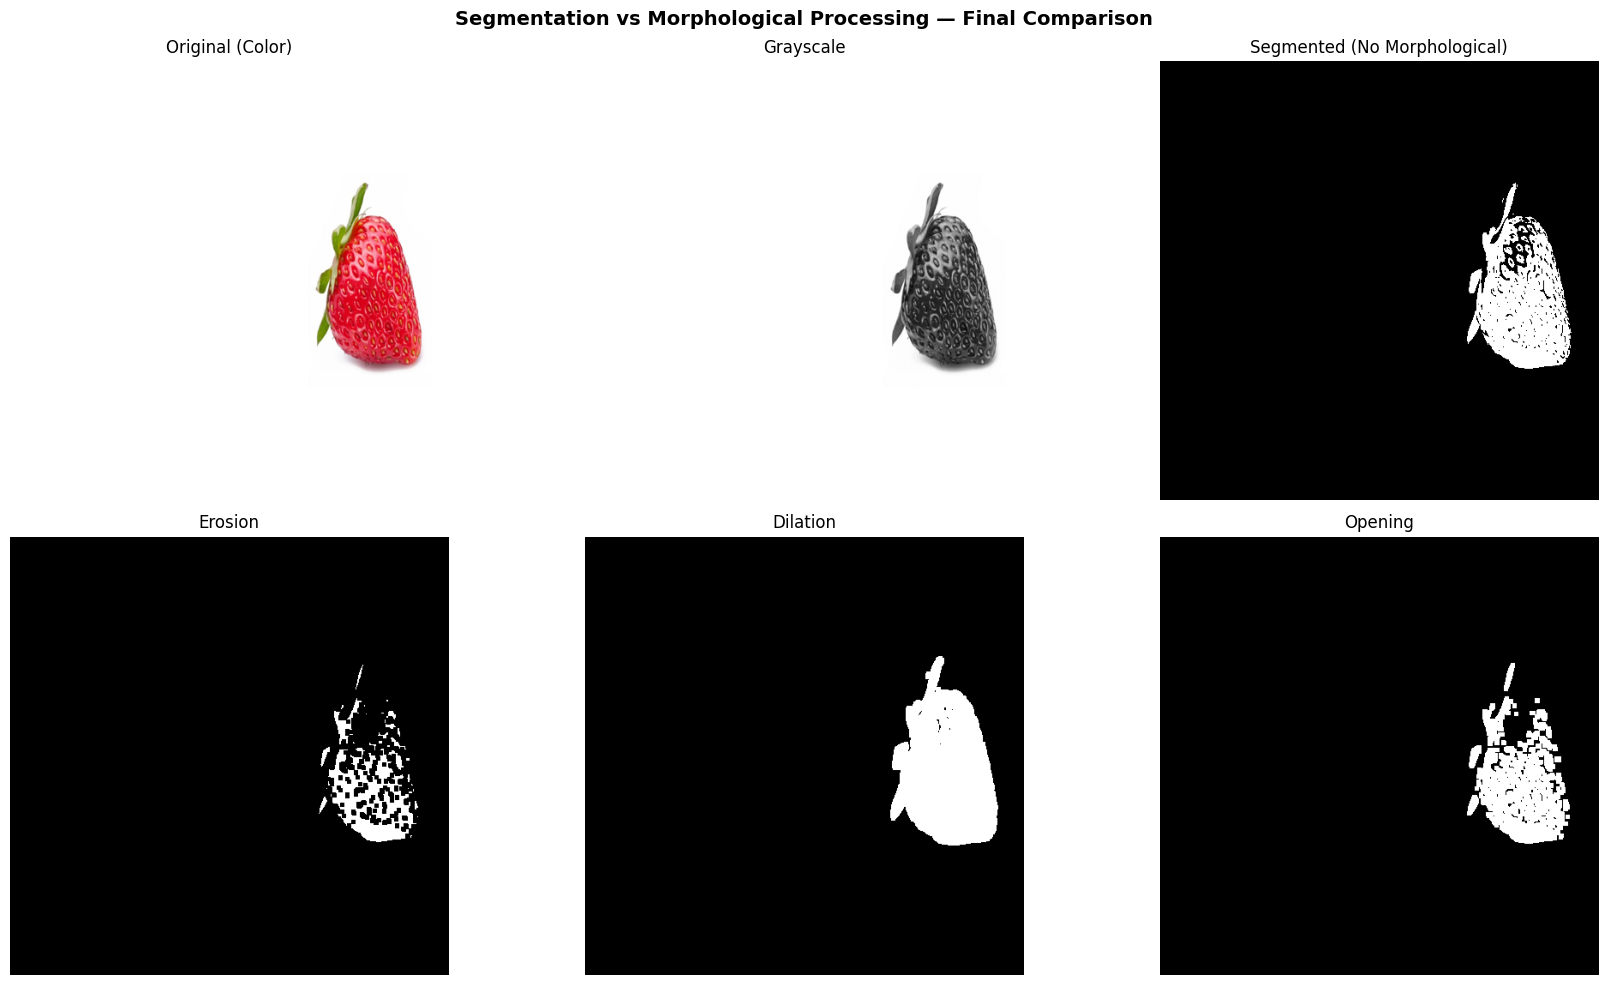

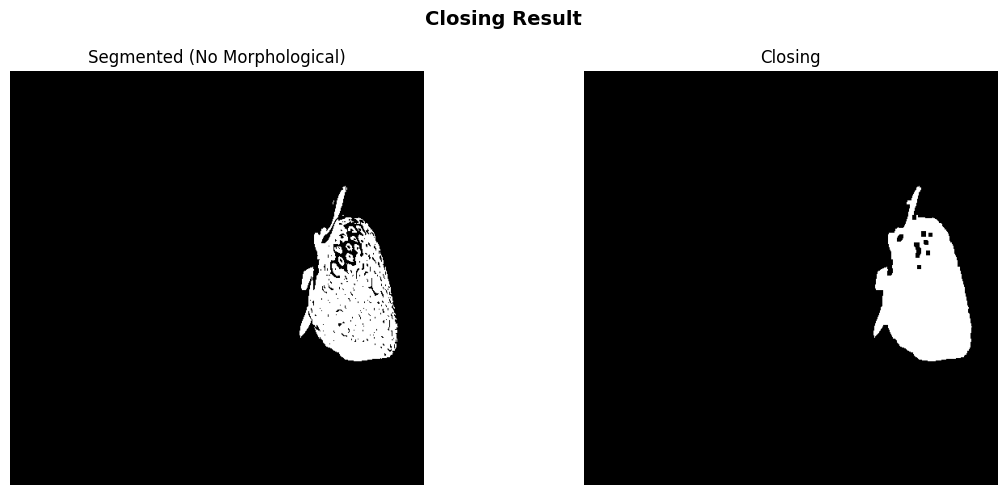

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Segmentation vs Morphological Processing — Final Comparison", fontsize=14, fontweight='bold')

axes[0, 0].imshow(img, )
axes[0, 0].set_title("Original (Color)")
axes[0, 0].axis('off')

axes[0, 1].imshow(img_gray, cmap='gray')
axes[0, 1].set_title("Grayscale")
axes[0, 1].axis('off')

axes[0, 2].imshow(segmented, cmap='gray')
axes[0, 2].set_title("Segmented (No Morphological)")
axes[0, 2].axis('off')

axes[1, 0].imshow(eroded, cmap='gray')
axes[1, 0].set_title("Erosion")
axes[1, 0].axis('off')

axes[1, 1].imshow(dilated, cmap='gray')
axes[1, 1].set_title("Dilation")
axes[1, 1].axis('off')

axes[1, 2].imshow(opened, cmap='gray')
axes[1, 2].set_title("Opening")
axes[1, 2].axis('off')

plt.tight_layout()
plt.savefig("comparison.png", dpi=150, bbox_inches='tight')
plt.show()

# Show closing separately
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))
fig2.suptitle("Closing Result", fontsize=14, fontweight='bold')

axes2[0].imshow(segmented, cmap='gray')
axes2[0].set_title("Segmented (No Morphological)")
axes2[0].axis('off')

axes2[1].imshow(closed, cmap='gray')
axes2[1].set_title("Closing")
axes2[1].axis('off')

plt.tight_layout()
plt.savefig("closing_comparison.png", dpi=150, bbox_inches='tight')
plt.show()